# Modèles d'estimation du délai

Ce notebook choisit le modèle qui **estime le délai de livraison** d'une commande. La promesse,
construite à partir d'un quantile élevé sera étudiée ensuite.

Tous les modèles sont évalués avec le protocole définit précédemment : réentraînement le 1ᵉʳ de chaque mois sur
les commandes déjà livrées, puis prédiction des commandes du mois, de novembre 2017 à avril 2018. La
métrique est la MAE, en jours. **La barre à battre est 6,44 jours**, la médiane du délai sur le
trajet de la commande.

Le modèle reçoit les 16 colonnes brutes autorisées et calcule lui-même ses variables. C'est
le même pipeline qui servira dans l'API.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import ParameterGrid, train_test_split

from olist_promesse.donnees import charger_commandes, selectionner_commandes
from olist_promesse.evaluation import (
    CIBLE,
    MOIS_VALIDATION,
    decoupage_mensuel,
    par_mois,
    predire_par_mois,
    resumer_estimation,
)
from olist_promesse.modeles import QuantileParGroupe, modele_gradient_boosting
from olist_promesse.variables import COLONNES_BRUTES

BLEU, VERT, GRIS, GRIS_CLAIR = "#2a78d6", "#1baf7a", "#52514e", "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.labelcolor": GRIS,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.titlelocation": "left",
})

commandes, _ = selectionner_commandes(charger_commandes())
TRAJET = [["seller_state", "customer_state"], ["customer_state"]]


def mae_par_mois(predictions: dict) -> pd.DataFrame:
    """MAE de chaque modèle, mois par mois et sur l'ensemble des mois évalués."""
    return pd.DataFrame({nom: par_mois(commandes, p, resumer_estimation)["MAE (j)"] for nom, p in predictions.items()}).round(2)

## 1. Le gradient boosting face aux références

Le modèle retenu pour l'essai est un gradient boosting d'arbres (`HistGradientBoostingRegressor`) :
- il capte les effets non linéaires et les interactions, par exemple une même distance qui ne coûte
  pas le même délai selon l'État du client
- il traite nativement les catégories et les valeurs manquantes
- il s'entraîne en quelques secondes sur 60 000 commandes

Il minimise l'erreur absolue, il vise donc le délai médian qui est la prédiction optimale pour la
MAE.

In [2]:
modeles = {
    "médiane globale": QuantileParGroupe(),
    "médiane par trajet": QuantileParGroupe(niveaux=TRAJET),
    "gradient boosting": modele_gradient_boosting(),
}
predictions = {nom: predire_par_mois(modele, commandes, MOIS_VALIDATION, COLONNES_BRUTES) for nom, modele in modeles.items()}
mae_par_mois(predictions)

,médiane globale,médiane par trajet,gradient boosting
2017-11,7.41,6.55,6.26
2017-12,7.85,6.85,6.59
2018-01,6.84,5.87,5.55
2018-02,8.70,7.54,7.28
2018-03,8.68,7.44,6.98
2018-04,5.85,4.45,4.15
ensemble,7.54,6.44,6.12


In [3]:
pd.DataFrame({nom: resumer_estimation(commandes, p) for nom, p in predictions.items()}).T.round(2)

,MAE (j),erreur médiane (j)
médiane globale,7.54,-1.71
médiane par trajet,6.44,-1.66
gradient boosting,6.12,-1.51


Le gradient boosting fait **6,12 jours de MAE, contre 6,44 pour la médiane par trajet** soit 0,3 jour de
moins (5 % d'erreur en moins). Le gain est modeste mais régulier, le modèle bat la référence
chaque mois, de 0,26 à 0,46 jour.

Comme les références, il sous-estime le délai pendant les mois difficiles (erreur médiane de
-1,5 jour sur l'ensemble). Mieux exploiter les variables ne corrige pas ce décalage, qui vient de la
dérive (section 4).

## 2. Viser la médiane ou la moyenne ?

La même famille de modèles peut minimiser l'erreur quadratique. Il vise alors le délai moyen, plus
élevé que la médiane puisque la distribution est asymétrique à droite. On compare les deux, ainsi que le modèle
médian décalé d'une constante.

In [4]:
predictions_perte = {
    "erreur absolue (médiane)": predictions["gradient boosting"],
    "erreur quadratique (moyenne)": predire_par_mois(modele_gradient_boosting(loss="squared_error"), commandes, MOIS_VALIDATION, COLONNES_BRUTES),
}
for decalage, nom in [(0.5, "médiane + 0,5 jour"), (1.0, "médiane + 1 jour"), (1.5, "médiane + 1,5 jour")]:
    predictions_perte[nom] = predictions["gradient boosting"] + decalage

display(mae_par_mois(predictions_perte))
pd.DataFrame({nom: resumer_estimation(commandes, p) for nom, p in predictions_perte.items()}).T.round(2)

,erreur absolue (médiane),erreur quadratique (moyenne),"médiane + 0,5 jour",médiane + 1 jour,"médiane + 1,5 jour"
2017-11,6.26,6.03,6.10,5.97,5.90
2017-12,6.59,6.27,6.40,6.24,6.13
2018-01,5.55,5.49,5.48,5.46,5.48
2018-02,7.28,6.79,7.07,6.90,6.77
2018-03,6.98,6.65,6.86,6.77,6.73
2018-04,4.15,4.67,4.28,4.45,4.66
ensemble,6.12,5.97,6.02,5.95,5.93


,MAE (j),erreur médiane (j)
erreur absolue (médiane),6.12,-1.51
erreur quadratique (moyenne),5.97,-0.29
"médiane + 0,5 jour",6.02,-1.01
médiane + 1 jour,5.95,-0.51
"médiane + 1,5 jour",5.93,-0.01


L'erreur quadratique semble meilleure : 5,97 jours de MAE contre 6,12. Mais ajouter simplement un jour
à toutes les prédictions du modèle médian donne le même résultat (5,95 jours), et un jour et demi fait
mieux encore (5,93). Le gain ne vient donc pas d'un meilleur modèle, mais d'un biais vers le haut. De novembre à mars, les délais ont été plus longs que dans le passé appris, et surestimer compensait
cette dérive.

Avril le confirme d'ailleurs, quand les délais baissent le modèle médian redevient le meilleur (4,15 jours,
contre 4,67 pour l'erreur quadratique). Les mois de test, de mai à juillet 2018, sont justement plus
rapides que le passé (exploration, section 4).

La décision prise est de garder l'erreur absolue. Choisir un modèle parce qu'il est biaisé dans le sens qui arrangeait
la période de validation reviendrait à miser sur le fait que la dérive continuera dans le même sens.

## 3. Le réglage des hyperparamètres

In [5]:
grille = ParameterGrid({
    "learning_rate": [0.05, 0.1],
    "max_leaf_nodes": [15, 63],
    "min_samples_leaf": [20, 100],
})
reglages = []
for parametres in grille:
    modele = modele_gradient_boosting(max_iter=500, **parametres)
    prediction = predire_par_mois(modele, commandes, MOIS_VALIDATION, COLONNES_BRUTES)
    reglages.append({**parametres, "MAE (j)": resumer_estimation(commandes, prediction)["MAE (j)"]})
pd.DataFrame(reglages).sort_values("MAE (j)").round(3)

,learning_rate,max_leaf_nodes,min_samples_leaf,MAE (j)
7,0.10,63,100,6.106
3,0.05,63,100,6.111
4,0.10,15,20,6.111
2,0.05,63,20,6.112
6,0.10,63,20,6.113
1,0.05,15,100,6.116
0,0.05,15,20,6.119
5,0.10,15,100,6.119


Les huit combinaisons donnent la même MAE à 0,01 jour près, et le réglage par défaut est dans cette
fourchette (6,116 jours). Plus d'arbres, des arbres plus profonds ou plus de régularisation ne changent
rien. Pour ce problème, le modèle n'est pas limité par sa complexité. On garde les réglages par défaut,
l'arrêt anticipé choisissant lui-même le nombre d'arbres.

## 4. Ce qui limite le modèle : la dérive

Pour mesurer le coût de la dérive, on compare deux erreurs du même modèle, entraîné sur 80 % des
commandes d'entraînement :
- sur les 20 % restants, tirés au hasard dans la même période soit ce que
  mesurerait une validation croisée classique
- sur le mois suivant soit la situation réelle de la production

In [6]:
lignes = {}
for mois in MOIS_VALIDATION:
    entrainement, evaluation = decoupage_mensuel(commandes, mois)
    apprentissage, tirage = train_test_split(entrainement, test_size=0.2, random_state=0)
    modele = modele_gradient_boosting().fit(apprentissage[COLONNES_BRUTES], apprentissage[CIBLE])
    lignes[str(mois)] = {
        "gradient boosting, même période": mean_absolute_error(tirage[CIBLE], modele.predict(tirage[COLONNES_BRUTES])),
        "gradient boosting, mois suivant": mean_absolute_error(evaluation[CIBLE], modele.predict(evaluation[COLONNES_BRUTES])),
    }
derive = pd.DataFrame.from_dict(lignes, orient="index")
derive["médiane par trajet, mois suivant"] = mae_par_mois(predictions)["médiane par trajet"].drop("ensemble")
derive.loc["moyenne"] = derive.mean()
derive.round(2)

,"gradient boosting, même période","gradient boosting, mois suivant","médiane par trajet, mois suivant"
2017-11,3.90,6.26,6.55
2017-12,3.83,6.62,6.85
2018-01,4.11,5.56,5.87
2018-02,4.26,7.28,7.54
2018-03,4.41,6.99,7.44
2018-04,4.68,4.14,4.45
moyenne,4.20,6.14,6.45


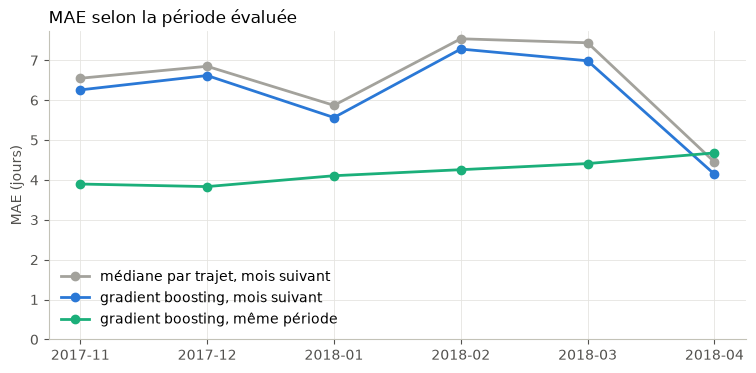

In [7]:
mois_evalues = derive.index.drop("moyenne")
fig, ax = plt.subplots()
for colonne, couleur in [
    ("médiane par trajet, mois suivant", GRIS_CLAIR),
    ("gradient boosting, mois suivant", BLEU),
    ("gradient boosting, même période", VERT),
]:
    ax.plot(mois_evalues, derive.loc[mois_evalues, colonne], color=couleur, lw=2, marker="o", label=colonne)
ax.legend(frameon=False, loc="lower left")
ax.set(title="MAE selon la période évaluée", ylabel="MAE (jours)", ylim=(0, None))
plt.show()

Sur des commandes de la même période, le modèle se trompe de **4,2 jours** en moyenne tandis que sur le mois
suivant il se trompe de **6,1 jours**. La dérive coûte donc environ 2 jours d'erreur, soit un tiers de l'erreur
totale. C'est aussi l'erreur qu'aurait commise une validation croisée classique. Elle aurait ainsi annoncé
un modèle bien meilleur qu'il ne l'est en production.

Avril fait exception (4,1 jours sur le mois suivant contre 4,7 sur la même période). Les délais y
baissent, et le mois est plus facile à prédire que la période apprise.

Peut-on corriger la dérive en donnant plus de poids aux commandes récentes ? On essaie avec une méthode simple : le poids
d'une commande d'entraînement est divisé par deux tous les 30, 60 ou 90 jours d'ancienneté.

In [8]:
class PonderationRecente(RegressorMixin, BaseEstimator):
    """Entraîne le modèle en divisant le poids des commandes par deux tous les `demi_vie_jours` d'ancienneté."""

    def __init__(self, modele=None, demi_vie_jours=60):
        self.modele = modele
        self.demi_vie_jours = demi_vie_jours

    def fit(self, X, y):
        achat = X["order_purchase_timestamp"]
        anciennete_jours = (achat.max() - achat).dt.total_seconds() / 86400
        poids = 0.5 ** (anciennete_jours / self.demi_vie_jours)
        self.modele_ = clone(self.modele).fit(X, y, modele__sample_weight=poids.to_numpy())
        return self

    def predict(self, X):
        return self.modele_.predict(X)


predictions_poids = {"sans pondération": predictions["gradient boosting"]}
for demi_vie in [30, 60, 90]:
    modele = PonderationRecente(modele_gradient_boosting(), demi_vie)
    predictions_poids[f"demi-vie de {demi_vie} jours"] = predire_par_mois(modele, commandes, MOIS_VALIDATION, COLONNES_BRUTES)
mae_par_mois(predictions_poids)

,sans pondération,demi-vie de 30 jours,demi-vie de 60 jours,demi-vie de 90 jours
2017-11,6.26,6.37,6.29,6.28
2017-12,6.59,6.60,6.57,6.58
2018-01,5.55,5.42,5.43,5.45
2018-02,7.28,7.04,7.05,7.11
2018-03,6.98,6.68,6.71,6.73
2018-04,4.15,4.36,4.31,4.26
ensemble,6.12,6.06,6.04,6.05


La pondération ne gagne que 0,06 à 0,07 jour, et dégrade avril (4,26 à 4,36 jours contre 4,15). Le
passé récent ne permet pas de mieux anticiper la dérive (un évènement ponctuel arrive sans prévenir, comme le Black Friday par exemple). La pondération n'est finalement pas retenue. Son gain est trop faible et trop irrégulier pour
justifier un réglage de plus.

La dérive devra donc être traitée là où elle coûte le plus, c'est-à-dire dans la promesse. Un modèle qui
sous-estime le délai pendant une crise promet trop court, et le taux de retard s'envole.

## Synthèse

1. **Modèle retenu** : gradient boosting sur les 14 variables, minimisant l'erreur absolue, avec les
   réglages par défaut.
2. **MAE de 6,12 jours** sur les mois de validation, contre 6,44 pour la médiane par trajet
   (-5 %). Le modèle bat la référence chaque mois.
3. **L'erreur quadratique n'est pas retenue** : son avantage apparent vient d'un biais qui compensait
   la dérive de la période de validation.
4. **Le réglage des hyperparamètres ne change rien** (environ 0,01 jour d'écart).
5. **La dérive coûte environ 2 jours de MAE** : 4,2 jours sur la même période contre 6,1 sur le mois
   suivant. Une pondération des commandes récentes ne la corrige pas.
6. **Pour la promesse**, le même pipeline visera un quantile élevé
   (`loss="quantile"`). Le niveau visé devra être calibré pour tenir le taux de retard malgré la
   dérive.